In [33]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("netflix_titles.csv")
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [34]:
df=df.drop(["director","cast","description","show_id","date_added"],axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   type          8807 non-null   str  
 1   title         8807 non-null   str  
 2   country       7976 non-null   str  
 3   release_year  8807 non-null   int64
 4   rating        8803 non-null   str  
 5   duration      8804 non-null   str  
 6   listed_in     8807 non-null   str  
dtypes: int64(1), str(6)
memory usage: 481.8 KB


In [35]:
df["country"]=df["country"].fillna("unknown")


In [36]:
df=df.dropna(subset=["rating"])
df.info()


<class 'pandas.DataFrame'>
Index: 8803 entries, 0 to 8806
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   type          8803 non-null   str  
 1   title         8803 non-null   str  
 2   country       8803 non-null   str  
 3   release_year  8803 non-null   int64
 4   rating        8803 non-null   str  
 5   duration      8800 non-null   str  
 6   listed_in     8803 non-null   str  
dtypes: int64(1), str(6)
memory usage: 550.2 KB


In [44]:
movie_df=df[df["type"]=="Movie"]
movie_df["duration_time"]=df['duration'].str.extract('(\d+)')
movie_df=movie_df.dropna(subset=["duration_time"])
movie_df["duration_time"]=movie_df["duration_time"].astype(int)
movie_df.info()

<class 'pandas.DataFrame'>
Index: 6128 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   show_id        6128 non-null   str  
 1   type           6128 non-null   str  
 2   title          6128 non-null   str  
 3   director       5940 non-null   str  
 4   cast           5653 non-null   str  
 5   country        5688 non-null   str  
 6   date_added     6128 non-null   str  
 7   release_year   6128 non-null   int64
 8   rating         6126 non-null   str  
 9   duration       6128 non-null   str  
 10  listed_in      6128 non-null   str  
 11  description    6128 non-null   str  
 12  duration_time  6128 non-null   int64
dtypes: int64(2), str(11)
memory usage: 670.2 KB


<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\tania\AppData\Local\Temp\ipykernel_20108\2476913327.py:2: SyntaxWarning: invalid escape sequence '\d'
  movie_df["duration_time"]=df['duration'].str.extract('(\d+)')


#MOVIES VS TV SHOWS

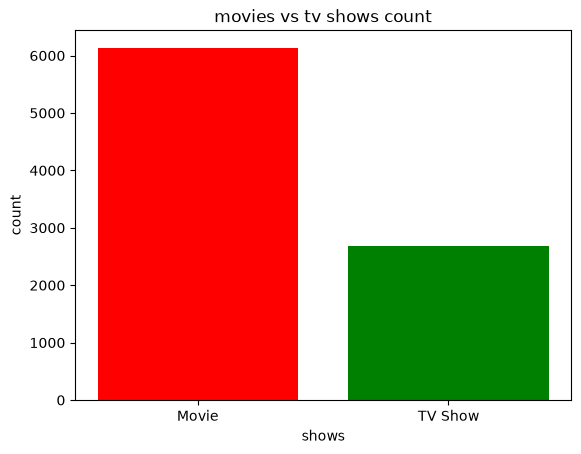

In [39]:
import matplotlib.pyplot as plt
df=pd.read_csv("netflix_titles.csv")
count_value=df['type'].value_counts()
plt.bar(count_value.index,count_value.values,color=["red","green"])
plt.xlabel("shows")
plt.ylabel("count")
plt.title("movies vs tv shows count")
plt.show()


Percentage of each content

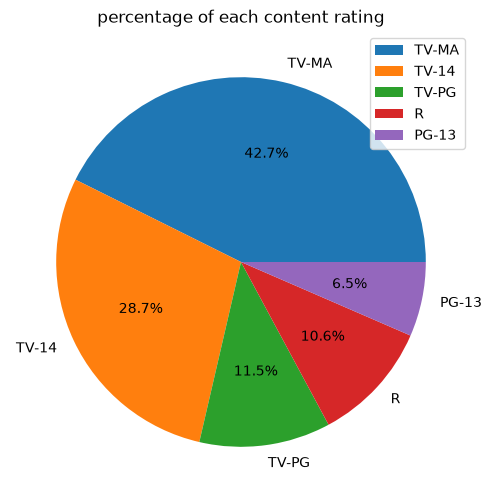

In [40]:
ratings=df["rating"].value_counts().head(5)
plt.figure(figsize=(6,6))
plt.pie(ratings, labels=ratings.index ,autopct="%1.1f%%")
plt.title("percentage of each content rating")
plt.legend(loc="upper right")
plt.show()

HOW HAS THE NUMBER OF RELEASE CHANGED OVER THE YEARS

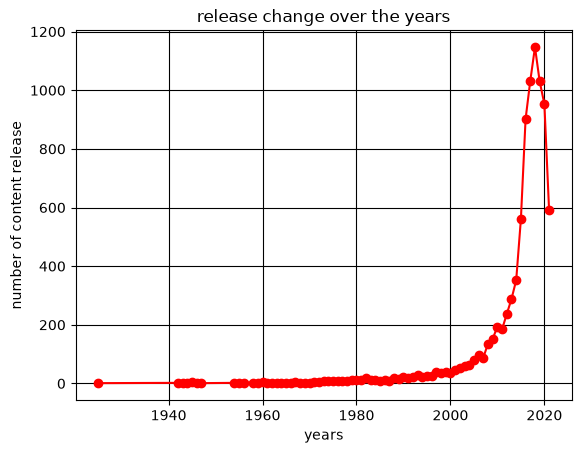

In [41]:
release=df["release_year"].value_counts().sort_index()
plt.plot(release.index,release.values,linestyle="-",color="red",marker="o")
plt.xlabel("years")
plt.ylabel("number of content release")
plt.title("release change over the years")
plt.grid(color="black")
plt.show()

DISTRIBUTION OF MOVIE DURATION

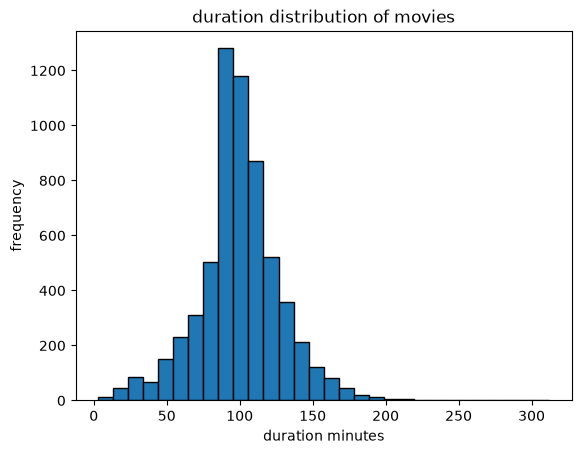

In [46]:
plt.hist(movie_df["duration_time"],bins=30,edgecolor="black")
plt.xlabel("duration minutes")
plt.ylabel("frequency")
plt.title("duration distribution of movies")
plt.show()


Relationship between relase year and number of shows

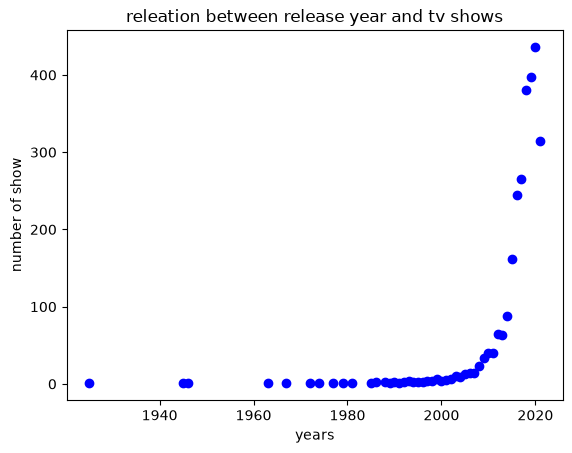

In [52]:
tv_df=df[df["type"]=="TV Show"]
tv_year=tv_df["release_year"]
show=tv_year.value_counts().sort_index()
plt.scatter(show.index,show.values,marker="o",color="blue")
plt.xlabel("years")
plt.ylabel("number of show")
plt.title("releation between release year and tv shows")
plt.show()



TOP 10 COUNTRIES WITH THE HIGHEST NUMBER OF SHOWS

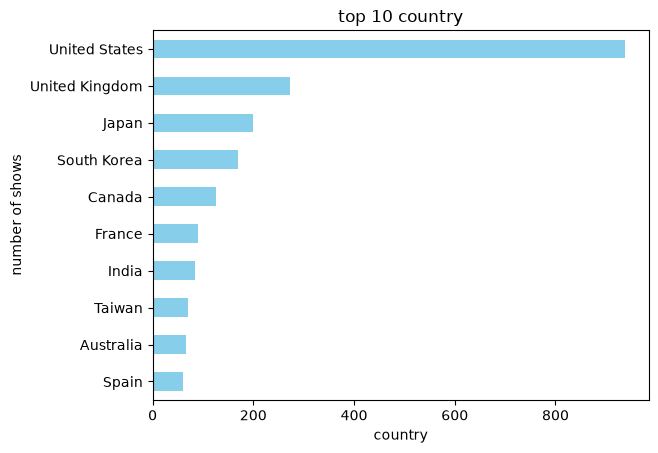

In [56]:
tv_df=tv_df.dropna(subset=["country"])
tv_df["country"]=tv_df["country"].str.split(", ")
tv_df=tv_df.explode("country")
countries=tv_df["country"].value_counts().head(10)
countries.sort_values().plot(kind="barh",color="skyblue")
plt.xlabel("country")
plt.ylabel("number of shows")
plt.title("top 10 country")
plt.show()



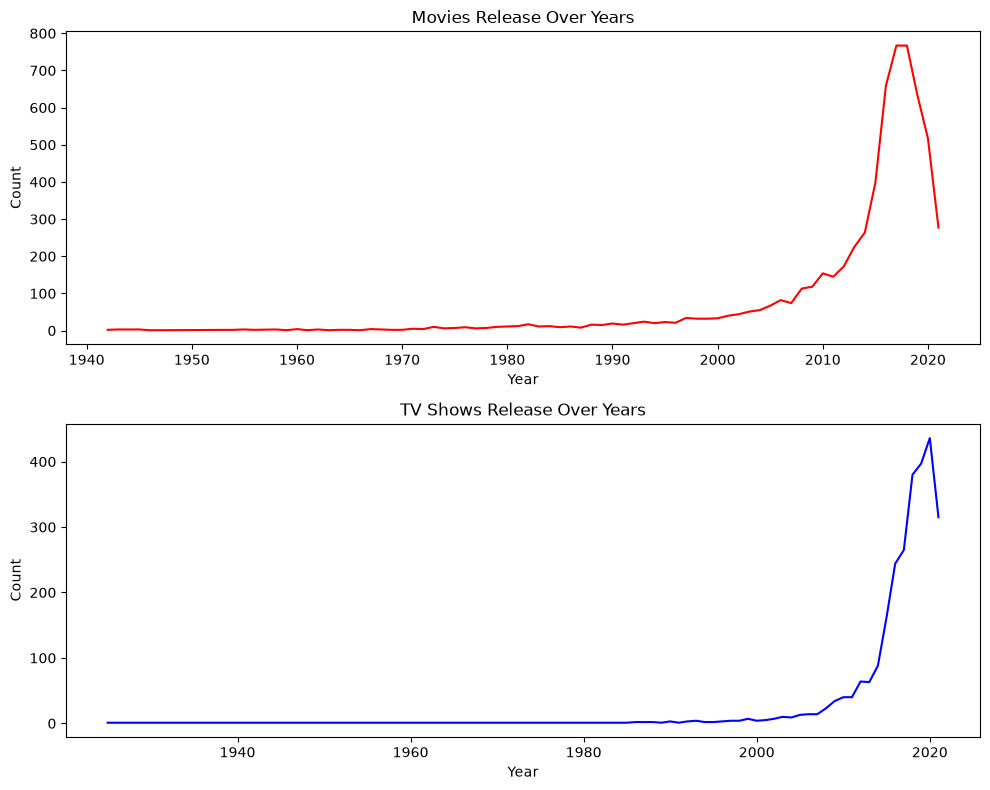

In [58]:
import matplotlib.pyplot as plt
movie_df = df[df['type'] == 'Movie']
tv_df = df[df['type'] == 'TV Show']

movie_year = movie_df['release_year'].value_counts().sort_index()
tv_year = tv_df['release_year'].value_counts().sort_index()

fig, ax = plt.subplots(2, 1, figsize=(10, 8))  

ax[0].plot(movie_year.index, movie_year.values, color='red')
ax[0].set_title("Movies Release Over Years")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Count")


ax[1].plot(tv_year.index, tv_year.values, color='blue')
ax[1].set_title("TV Shows Release Over Years")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Count")


plt.tight_layout()
plt.savefig("subplot.png")


plt.show()